# La banda de dependencia mostrada con cada agregado, y un veredicto de réplica honesto

**Pregunta:** ¿Qué pierde un lector cuando una cifra de capital agregado se muestra sin su banda de dependencia, y lleva cada
agregado que Contraste versiona la banda completa?

- **Nivel:** 4, métodos propuestos
- **Requisitos previos:** los notebooks 01 a 03 y 08 de este tema (la banda, sus cotas y la práctica publicada)
- **Tiempo de lectura:** unos 60 minutos

## Objetivos

Al terminar este notebook puedes:

- plantear la afirmación, que toda cifra de capital agregado se muestra con la banda completa y que solo la suma simple se
  etiqueta como capital, y comprobar su estructura en cada agregado versionado;
- decir por qué los seis agregados de cinco documentos son en realidad dos, y ejecutar las pruebas de cota y de signo del motor
  en cada uno;
- ver al motor devolver una banda completa, nunca un escalar, en su propio ejemplo de oro;
- medir qué habría escondido cada cifra suelta de la banda, con la distancia al resto de la banda y con las medidas de riesgo
  de modelo del motor;
- leer los registros que dicen que la réplica de los modelos supervisores, el caso C19, sigue planificada.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. Un notebook nunca instala nada por sí mismo. Los identificadores de las pruebas del motor se imprimen tal como los escribe el motor. Sus mensajes y notas están escritos en inglés: el árbol inglés los imprime como están, y este árbol imprime una traducción desde una tabla del notebook que falla si el motor cambia el texto.

La celda siguiente importa lo que usa el notebook e imprime las versiones de los paquetes, para que las compares con las fijadas.

In [1]:
# Importaciones, versiones y lector de los documentos versionados (tres carpetas bajo la raíz del repositorio)
import hashlib
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.aggregation import band as rv_band
from riskvalidation.aggregation import bounds
from riskvalidation.aggregation import copulas as cop
from riskvalidation.aggregation import model_risk
from riskvalidation.aggregation import simple
from riskvalidation.validation import aggregation as agg_tests
from scipy import stats

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))
ROOT = Path("../../..").resolve()
DERIVED = ROOT / "data" / "derived"


def read_json(relative):
    return json.loads((DERIVED / relative).read_text(encoding="utf-8"))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Este notebook lee cada agregado que **C18** versiona, y los registros que dicen qué está y qué no está construido.

- **Propietario y licencia:** los documentos los escribe el flujo sin conexión de este repositorio (`data-pipeline/pipeline/cases/c18/`) con el motor `riskvalidation` y se versionan en `data/derived/C18/`. Las trayectorias de escenario vienen de la Reserva Federal (dominio público), de la EBA y la ESRB (reproducción autorizada citando la fuente) y de la NGFS (solo derivado: únicamente las pocas variables que usa el caso). **Banco Andino es un banco sintético**: su cartera y su capital están calibrados a agregados públicos, y las trayectorias son trayectorias reales de Estados Unidos y de la zona euro trasladadas a su punto de partida, así que los satélites son una adaptación calibrada en EE. UU.
- **Estatus de verdad:** `synthetic-calibrated`. No hay respuesta publicada para el banco; las verificaciones de este notebook son recálculos de números versionados con el motor, no comparaciones con un resultado publicado.
- **Horneado con:** `riskvalidation` 0.8.1 (semilla 42), la versión que instala este notebook, así que se espera que un recálculo coincida hasta el redondeo.
- **Archivos leídos:** los cuatro documentos de escenario `data/derived/C18/baseline.json`, `eba-2025-adverse.json`, `fed-2026-severely-adverse.json` y `ngfs-delayed-transition.json` y el documento de agregación `t-copula-baseline.json` (cada uno lleva `outputs.aggregation`, y el último también el estrés mercado-crédito), el índice de casos `data/derived/manifests/index.json`, el registro de preparación `data/derived/readiness.json` y el contrato de estrés del motor `docs/contracts/engine/stress-api.md` (su párrafo de alcance registra por qué el caso C19 sigue planificado).
- **Qué se afirma y qué no.** La afirmación es sobre lo que **hace Contraste**: muestra la banda. No es una afirmación de que nadie más lo hace, lo que la investigación no pudo establecer más allá de su propia búsqueda.

In [2]:
# El bloque de agregación de cada documento versionado, y el mismo bloque bajo el estrés mercado-crédito 0,8
SCENARIOS = ("baseline", "eba-2025-adverse", "fed-2026-severely-adverse", "ngfs-delayed-transition")
blocks = {name: read_json(f"C18/{name}.json")["outputs"]["aggregation"] for name in SCENARIOS}
second = read_json("C18/t-copula-baseline.json")["outputs"]
STRESSED = "t-copula-baseline, market-credit 0.8"
blocks["t-copula-baseline"] = second["aggregation"]
blocks[STRESSED] = second["correlation_stress"]["aggregation"]
LIGHT = {"green": "verde", "amber": "ámbar", "red": "rojo"}
NAMES = {"lower-bound": "cota inferior", "simple-sum": "suma simple",
         "variance-covariance": "varianza-covarianza", "gaussian-copula": "cópula gaussiana",
         "t-copula": "cópula t", "worst-case": "peor caso"}
print("documentos con un agregado", len(blocks))

documentos con un agregado 6


## Método

### Paso 1: la afirmación, comprobada en cada agregado

**La afirmación.** Toda cifra de capital agregado de C18 se muestra con la **banda** de métodos de agregación sobre las mismas marginales, un horizonte y un nivel de confianza: la cota inferior, la suma simple, la regla de la raíz cuadrada, la cópula gaussiana, una cópula t por cada grado de libertad del conjunto nombrado y el peor caso exacto por el algoritmo de reordenamiento, en ese orden. La suma simple es la única fila rotulada **capital principal**; toda otra fila, la asignación de Euler y las medidas de riesgo de modelo se rotulan **información, no capital**. El caso nunca muestra una sola cifra diversificada.

La celda siguiente comprueba esa afirmación en cada agregado: el número y el orden de las filas, el estado de cada una, que
exactamente una fila es el titular y es la suma simple, la brecha de aditividad de Euler y la etiqueta del riesgo de modelo.
También calcula la huella de los seis bloques para mostrar cuáles son uno solo.

In [3]:
# La estructura de la banda en cada agregado versionado, y la huella de cada bloque
EXPECTED = ["lower-bound", "simple-sum", "variance-covariance", "gaussian-copula", "t-copula", "t-copula", "t-copula",
            "worst-case"]
for name, block in blocks.items():
    methods = [row["method"] for row in block["band"]]
    headline = [row["method"] for row in block["band"] if row["status"] == "headline-capital"]
    others = sorted({row["status"] for row in block["band"] if row["method"] != "simple-sum"})
    gap = block["euler"]["additivity"]["relative_error"]
    print(f"{name:38s} filas {len(methods)} orden indicado {methods == EXPECTED} {headline} {others}")
    print(f"{'':38s} brecha de Euler {gap:.1e} riesgo de modelo {block['model_risk']['status']}",
          block["confidence_level"], block["horizon_years"])
dump = {name: json.dumps(block, sort_keys=True).encode("utf-8") for name, block in blocks.items()}
digest = {name: hashlib.sha256(raw).hexdigest() for name, raw in dump.items()}
same = [name for name in blocks if digest[name] == digest["baseline"]]
print("bloques idénticos al de la base", same)
print("agregados distintos entre los seis", len(set(digest.values())))

baseline                               filas 8 orden indicado True ['simple-sum'] ['information-not-capital']
                                       brecha de Euler 1.6e-16 riesgo de modelo information-not-capital 0.999 1
eba-2025-adverse                       filas 8 orden indicado True ['simple-sum'] ['information-not-capital']
                                       brecha de Euler 1.6e-16 riesgo de modelo information-not-capital 0.999 1
fed-2026-severely-adverse              filas 8 orden indicado True ['simple-sum'] ['information-not-capital']
                                       brecha de Euler 1.6e-16 riesgo de modelo information-not-capital 0.999 1
ngfs-delayed-transition                filas 8 orden indicado True ['simple-sum'] ['information-not-capital']
                                       brecha de Euler 1.6e-16 riesgo de modelo information-not-capital 0.999 1
t-copula-baseline                      filas 8 orden indicado True ['simple-sum'] ['information-not-capital']
  

### Paso 2: recalcular lo que se puede recalcular, en cada agregado

La estructura no basta: las filas deben ser correctas. Dos filas de la banda dependen solo de los capitales de las marginales y de la matriz de correlación, así que el motor las recalcula exactamente desde cada documento: la suma simple y la regla de la raíz cuadrada. Las reglas que atan el resto son las pruebas del motor: `worst_case_bracket` (toda fila dentro del intervalo) y `diversification_sign` (ninguna fila diversificada sobre la suma simple), y el documento con estrés debe tener una fila de raíz cuadrada mayor que el base, porque una correlación más alta no puede bajar el capital.

La celda siguiente recalcula esas dos filas con el motor en cada uno de los seis agregados e informa si son las versionadas, la
única verificación de reproducción de este notebook.

In [4]:
# Recalcular con el motor las dos filas en forma cerrada de cada agregado
exact = {}
for name, block in blocks.items():
    ec = np.array([m["ec_clp_m"] for m in block["marginals"]])
    corr = np.array(block["correlation"]["matrix"])
    rows = {(r["method"], r["nu"]): r["capital_clp_m"] for r in block["band"]}
    exact[name] = np.isclose(simple.simple_sum(ec), rows[("simple-sum", None)])
    exact[name] = exact[name] and np.isclose(simple.variance_covariance(ec, corr), rows[("variance-covariance", None)])
    print(f"{name:38s} {bool(exact[name])}")

baseline                               True
eba-2025-adverse                       True
fed-2026-severely-adverse              True
ngfs-delayed-transition                True
t-copula-baseline                      True
t-copula-baseline, market-credit 0.8   True


La celda siguiente ejecuta las pruebas `worst_case_bracket` y `diversification_sign` del motor sobre cada uno de los seis
agregados e imprime la luz de cada una.

In [5]:
# La prueba de cota y la prueba de signo sobre cada agregado
kinds = ("variance-covariance", "gaussian-copula", "t-copula")
for name, block in blocks.items():
    rows = {(r["method"], r["nu"]): r["capital_clp_m"] for r in block["band"]}
    between = [v for (method, nu), v in rows.items() if method not in ("lower-bound", "worst-case")]
    bracket = agg_tests.worst_case_bracket(rows[("lower-bound", None)], between, rows[("worst-case", None)])
    factors = [r["diversification_factor"] for r in block["band"] if r["method"] in kinds]
    sign = agg_tests.diversification_sign(factors)
    print(f"{name:38s} {LIGHT[bracket.light.value]:6s} {LIGHT[sign.light.value]}")

baseline                               verde  verde
eba-2025-adverse                       verde  verde
fed-2026-severely-adverse              verde  verde
ngfs-delayed-transition                verde  verde
t-copula-baseline                      verde  verde
t-copula-baseline, market-credit 0.8   verde  verde


La celda siguiente dibuja lado a lado la banda de los dos agregados distintos, el base y el que tiene la correlación
mercado-crédito subida a 0,8, con el titular marcado.

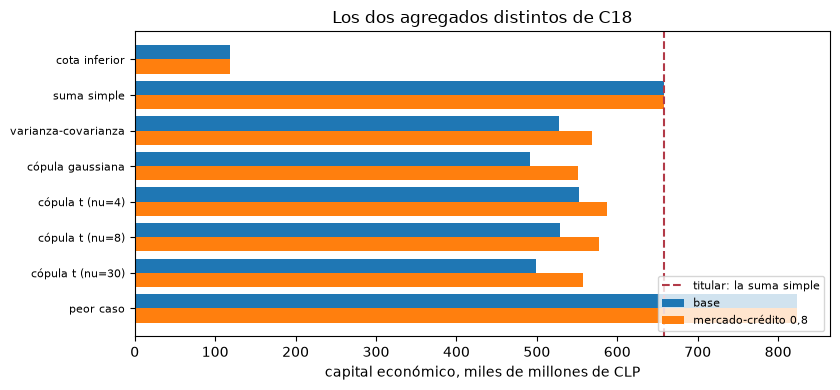

fila de la raíz cuadrada, base y estresada 528106.3 568520.5


In [6]:
# La banda de los dos agregados distintos, base y estresado, con el titular marcado
pair = {"base": blocks["baseline"], "mercado-crédito 0,8": blocks[STRESSED]}
fig, ax = plt.subplots(figsize=(8.5, 4))
y = np.arange(len(EXPECTED))[::-1]
for k, (label, block) in enumerate(pair.items()):
    ax.barh(y + (0.2 if k == 0 else -0.2), [r["capital_clp_m"] / 1e3 for r in block["band"]], height=0.4, label=label)
ax.axvline(blocks["baseline"]["headline"]["capital_clp_m"] / 1e3, color="#b23a48", linestyle="--",
           label="titular: la suma simple")
rows = blocks["baseline"]["band"]
ax.set_yticks(y)
ax.set_yticklabels([NAMES[r["method"]] + (f" (nu={r['nu']:g})" if r["nu"] else "") for r in rows], fontsize=8)
ax.set_xlabel("capital económico, miles de millones de CLP")
ax.set_title("Los dos agregados distintos de C18")
ax.legend(fontsize=8, loc="lower right")
fig.tight_layout()
plt.show()
vc = {name: next(r["capital_clp_m"] for r in blocks[name]["band"] if r["method"] == "variance-covariance")
      for name in ("t-copula-baseline", STRESSED)}
base_vc, stress_vc = vc["t-copula-baseline"], vc[STRESSED]
print("fila de la raíz cuadrada, base y estresada", round(base_vc, 1), round(stress_vc, 1))

Los seis bloques son dos agregados. La agregación no depende del escenario, así que los documentos base, EBA, Reserva Federal,
NGFS y t-copula llevan el mismo bloque, con la misma huella, y el sexto es ese bloque bajo el estrés mercado-crédito. Cada uno
tiene ocho filas en el orden indicado, una fila titular que es la suma simple, 658.046 millones de pesos en ambos, y siete
filas etiquetadas como información, un horizonte y un nivel, una brecha de Euler de 1,6e-16, y un bloque de riesgo de modelo
etiquetado como información. Las filas en forma cerrada se recalculan exactamente en los seis, ambas pruebas son verdes en los
seis, y la fila de la raíz cuadrada estresada, 568.521, queda sobre la base, 528.106. No se sigue que la banda se comprobó bajo
cuatro escenarios de estrés: se comprobó sobre el agregado base y sobre el estrés mercado-crédito.

### Paso 3: el motor devuelve la banda completa

La afirmación se apoya en el motor: `dependence_band` devuelve una `Band` de filas y un titular, nunca un escalar, y su
docstring da un ejemplo de oro: capitales 3 y 4, pérdidas esperadas 0 y correlación 0,5, que debe dar una fila de suma simple
de 7,0 y una fila de raíz cuadrada de 6,0828, con la cota inferior bajo la fila de la raíz cuadrada y el peor caso sobre ella.
La celda siguiente construye dos marginales normales con esos capitales al 99,9 por ciento, ejecuta `dependence_band` a un
tamaño reducido (200.000 simulaciones, 20.000 celdas de cota), imprime las filas con su estado y las dibuja.

objeto devuelto, titular, filas Band 7.0 7
cota inferior                  0.7601  0.1086 information-not-capital
suma simple                    7.0000  1.0000 headline-capital
varianza-covarianza            6.0828  0.8690 information-not-capital
cópula gaussiana               6.0912  0.8702 information-not-capital
cópula t (nu=4)                6.4726  0.9247 information-not-capital
cópula t (nu=30)               6.2208  0.8887 information-not-capital
peor caso                      7.4467  1.0638 information-not-capital


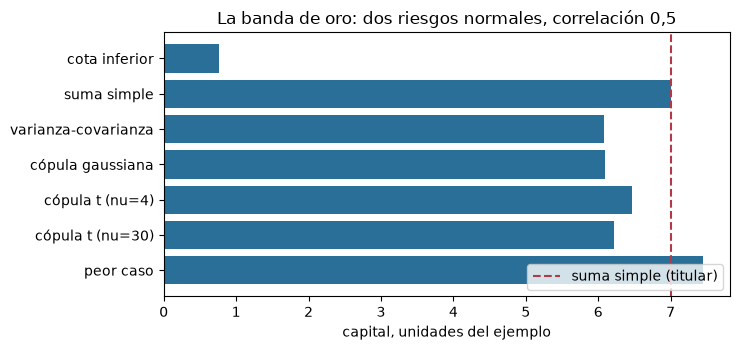

In [7]:
# El ejemplo de oro del motor: dos marginales normales con capitales 3 y 4, y la banda completa que devuelve
z = stats.norm.ppf(0.999)
normal_sample = stats.norm.ppf((np.arange(1, 100_001) - 0.5) / 100_000)
ppfs = [cop.marginal_ppf_sample(capital / z * normal_sample) for capital in (3.0, 4.0)]
golden = rv_band.dependence_band(ppfs, np.array([3.0, 4.0]), np.array([0.0, 0.0]), np.array([[1.0, 0.5], [0.5, 1.0]]),
                                 [4.0, 30.0], level=0.999, horizon_years=1, n_draws=200_000, seed=1,
                                 chunk_size=100_000, bounds_n=20_000, bounds_epsilon=1e-3,
                                 ec_consistency_tolerance=0.05)
print("objeto devuelto, titular, filas", type(golden).__name__, golden.headline, len(golden.rows))
labels = []
for row in golden.rows:
    labels.append(NAMES[row.method] + (f" (nu={row.nu:g})" if row.nu else ""))
    print(f"{labels[-1]:28s} {row.capital:8.4f} {row.diversification_factor:7.4f} {row.status}")
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.barh(labels[::-1], [r.capital for r in golden.rows][::-1], color="#2a6f97")
ax.axvline(golden.headline, color="#b23a48", linestyle="--", label="suma simple (titular)")
ax.set_xlabel("capital, unidades del ejemplo")
ax.set_title("La banda de oro: dos riesgos normales, correlación 0,5")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

El motor devuelve un objeto de la clase `Band` con siete filas y un titular de 7,0, nunca un escalar. La fila de la raíz
cuadrada es 6,0828, el valor de oro, la cópula gaussiana 6,0912 y las cópulas t 6,4726 y 6,2208, y las dos cotas son 0,7601 y
7,4467, de modo que el peor caso es 1,0638 veces la suma simple incluso con dos riesgos de este tamaño. Solo la suma simple se
etiqueta como capital titular. El orden se cumple sin los datos propios del caso, que es lo que hace de la afirmación una
propiedad del motor y no de un conjunto de documentos.

Las dos cotas de la banda salen de las cotas agudas de VaR del motor. La celda siguiente llama a `worst_var_bounds`
directamente sobre las mismas dos marginales, con el mismo número de celdas y tolerancia, e imprime el mejor y el peor VaR
junto a las dos filas de la banda, para que el lector vea de dónde salen esas filas.

In [8]:
# Las cotas agudas de VaR de las dos marginales de oro, llamadas directamente, junto a las dos filas de cota de
# la banda
direct = bounds.worst_var_bounds(ppfs, 0.999, 20_000, 1e-3, seed=1)
capital_of = {row.method: row.capital for row in golden.rows}
print("rango del mejor VaR, directo", np.round(direct.lower_range, 4))
print("rango del peor VaR, directo", np.round(direct.upper_range, 4))
print("filas de la banda: cota inferior y peor caso")
print(round(capital_of["lower-bound"], 4), round(capital_of["worst-case"], 4))

rango del mejor VaR, directo [0.7601 0.7719]
rango del peor VaR, directo [7.4466 7.4467]
filas de la banda: cota inferior y peor caso
0.7601 7.4467


La llamada directa da un mejor VaR entre 0,7601 y 0,7719 y un peor VaR entre 7,4466 y 7,4467, y las dos filas de la banda son
los extremos de esos rangos, 0,7601 y 7,4467, sin pérdida esperada que restar. Así, las dos cotas de la banda no son un modelo
aparte: son las cotas agudas del motor, el mejor y el peor VaR sobre toda dependencia posible, con las filas de las cópulas
entre ellas.

## Comparación

Lo que la investigación encontró como la práctica a superar (dossier 05, G.2 y G.3, con el estado de cada afirmación):

- El dossier **prescribe** la banda, "en lugar de una sola cifra diversificada", y advierte contra afirmar que los beneficios de diversificación son robustos; es una recomendación de la investigación, no una descripción de lo que hacen supervisores o herramientas.
- El Joint Forum encontró los modelos de agregación "un trabajo en progreso" en los que los supervisores en general no confían (el comunicado de prensa del 21 de octubre de 2010, https://www.bis.org/press/p101021.htm, trae ambas frases).
- Rosenberg y Schuermann (2006) muestran, en un estudio, que la elección de cópula importa modestamente mientras la aproximación aditiva sobrestima el riesgo en cerca de 30 a 40 por ciento; y Embrechts, Puccetti y Rueschendorf (2013) dan las cotas exactas de peor caso, un método que existe en la literatura.
- La investigación **no encontró una herramienta mantenida ni una práctica publicada que entregue la banda junto a cada agregado** (NO VERIFICADO más allá de la búsqueda del propio dossier).

Lo que existe, entonces, son los ingredientes: las cópulas, las cotas, la referencia y la recomendación. Lo que agrega el caso es **componerlos y no mostrar nunca una cifra sola**, como regla hecha cumplir por contrato (los requisitos CT-1811 y CT-1812 del caso) y por el tipo de retorno del motor.

In [9]:
# Leer las líneas de requisitos del caso que hacen de la banda una regla, para citar sus identificadores y
# pruebas
path = ROOT / "docs" / "design" / "features" / "c18" / "requirements.md"
for line in path.read_text(encoding="utf-8").splitlines():
    if line.startswith("| CT-1811") or line.startswith("| CT-1812"):
        identifier, text, gate = [cell.strip() for cell in line.strip("|").split("|")[:3]]
        print(identifier, "la prueba que falla cuando se viola", gate.split("::")[-1].strip("` "))

CT-1811 la prueba que falla cuando se viola test_the_headline_is_the_simple_sum_and_every_other_figure_is_information
CT-1812 la prueba que falla cuando se viola test_the_band_has_the_ladder_rows_and_the_euler_allocation_adds_up


## Evidencia

**La afirmación, la banda de dependencia con cada agregado.** Los pasos anteriores son su evidencia: la banda está en cada agregado versionado, en un orden fijo, con una fila principal y el resto rotulado información; sus filas en forma cerrada se recalculan exactamente; sus reglas estructurales pasan; su motor devuelve la banda completa; y los requisitos CT-1811 y CT-1812 la hacen una regla con puerta del caso. La afirmación se enuncia hasta donde llega la evidencia: **el caso muestra la banda, siempre**. Que la literatura no tenga un equivalente es NO VERIFICADO más allá de la búsqueda de la investigación.

Lo que la banda agrega sobre un solo número es medible en el documento versionado.

La celda siguiente toma la banda base y, para cada una de tres cifras sueltas, el titular solo, la cifra gaussiana sola y el
peor caso solo, calcula su factor de diversificación y las medidas de Barrieu y Scandolo del motor con esa cifra como
referencia. La figura dibuja el rango que cubren las otras siete filas, como múltiplo de cada cifra suelta.

el titular solo (suma simple)            658,046 bajo, sobre 6, 1
                                       las otras como múltiplos 0.18 - 1.25
                                       FD 1.000 AM 0.251 RM 0.235
la cifra gaussiana sola                  491,974 bajo, sobre 1, 6
                                       las otras como múltiplos 0.24 - 1.67
                                       FD 0.748 AM 0.674 RM 0.470
el peor caso solo                        823,332 bajo, sobre 7, 0
                                       las otras como múltiplos 0.14 - 0.80
                                       FD 1.251 AM 0.000 RM 0.000


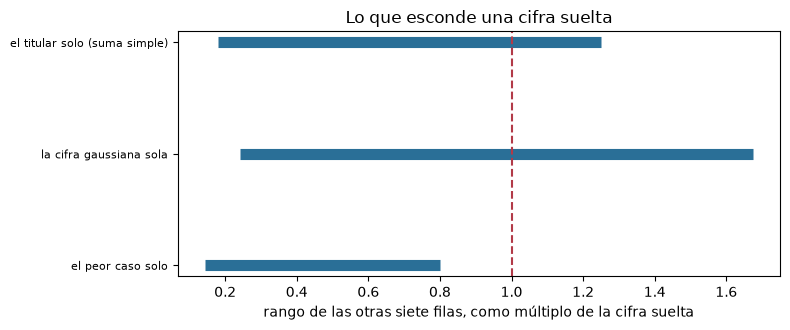

la banda tal como se muestra, millones de CLP 118,517.5 823,331.5


In [10]:
# Lo que habría dicho cada cifra suelta del agregado base y la parte de la banda que habría escondido
rows = {(r["method"], r["nu"]): r["capital_clp_m"] for r in blocks["baseline"]["band"]}
ec = np.array([m["ec_clp_m"] for m in blocks["baseline"]["marginals"]])
keys, capitals = list(rows), list(rows.values())
singles = (("el titular solo (suma simple)", ("simple-sum", None)),
           ("la cifra gaussiana sola", ("gaussian-copula", None)),
           ("el peor caso solo", ("worst-case", None)))
fig, ax = plt.subplots(figsize=(8, 3.4))
for k, (label, key) in enumerate(singles):
    others = [v / rows[key] for kk, v in rows.items() if kk != key]
    measures = model_risk.barrieu_scandolo(capitals, keys.index(key))
    factor = simple.diversification_factor(rows[key], ec)
    ax.hlines(-k, min(others), max(others), color="#2a6f97", linewidth=8)
    print(f"{label:38s} {rows[key]:9,.0f} bajo, sobre {sum(o < 1 for o in others)}, {sum(o > 1 for o in others)}")
    print(f"{'':38s} las otras como múltiplos {min(others):.2f} - {max(others):.2f}")
    print(f"{'':38s} FD {factor:.3f} AM {measures.am:.3f} RM {measures.rm:.3f}")
ax.axvline(1.0, color="#b23a48", linestyle="--")
ax.set_yticks([0, -1, -2])
ax.set_yticklabels([label for label, _ in singles], fontsize=8)
ax.set_xlabel("rango de las otras siete filas, como múltiplo de la cifra suelta")
ax.set_title("Lo que esconde una cifra suelta")
fig.tight_layout()
plt.show()
print("la banda tal como se muestra, millones de CLP", f"{min(capitals):,.1f}", f"{max(capitals):,.1f}")

Cada cifra suelta esconde la mayor parte de la banda. El titular solo esconde que el peor caso está sobre él, 6 filas bajo y 1
sobre, y que las otras van de 0,18 a 1,25 de él. La cifra gaussiana sola tiene 1 fila bajo y 6 sobre, y las otras van de 0,24
a 1,67 de ella, con un multiplicador de recargo de 0,674 para alcanzar el peor caso. El peor caso solo tiene las siete otras
bajo él, hasta 0,14 de él. Las tres barras son tres lectores del mismo documento que habrían salido con tres retratos
distintos del riesgo, y la banda completa abarca un factor de siete, de 118.518 a 823.332 millones de pesos. Eso es una medida
de la afirmación, no un conteo de filas.

## Resultados

La segunda parte de este notebook es una afirmación sobre **lo que no está construido**. Los casos del tema son C18, construido,
y C19, la réplica de los modelos supervisores de estrés contra tasas de pérdida publicadas («respuesta conocida»), que **sigue
planificado**. Este notebook no enseña nada de C19. Lee los tres registros que lo dicen: el índice de casos lista C19 con una
ruta de manifiesto, el registro de preparación dice que esa ruta falta y da la razón, y el contrato de estrés del motor
registra por qué: ningún tipo de cartera de la Reserva Federal es replicable desde el registro público, así que el motor no
tiene función de réplica supervisora ni prueba de réplica supervisora. La celda siguiente lee los tres registros e imprime lo
que dice cada uno.

In [11]:
# Leer los tres registros que dicen que C19 está planificado y no construido
index = read_json("manifests/index.json")
c19 = next(case for case in index["cases"] if case["case_id"] == "C19")
print("C19", c19["kind"], c19["manifest_path"], (DERIVED / c19["manifest_path"]).exists())
readiness = next(c for c in read_json("readiness.json")["contracts"] if c["id"] == "case-manifest")
print("registro de preparación: estado, faltante", readiness["state"], readiness["missing"])
stress_text = (ROOT / "docs" / "contracts" / "engine" / "stress-api.md").read_text(encoding="utf-8")
contract_text = " ".join(stress_text.split())
keeps = "keeps C19 (supervisory stress model replication) planned" in contract_text
print("el contrato de estrés mantiene C19 planificado", keeps)
none = "no supervisory function and no supervisory replication test" in contract_text
print("ninguna función ni prueba de réplica supervisora", none)
stress_cases = [case for case in index["cases"] if case["category_id"] == "capital-stress"]
built = sum((DERIVED / case["manifest_path"]).exists() for case in stress_cases)
print("casos de capital y estrés, con manifiesto", len(stress_cases), built)

C19 real manifests/C19.json False
registro de preparación: estado, faltante partial ['manifests/C19.json']
el contrato de estrés mantiene C19 planificado True
ninguna función ni prueba de réplica supervisora True
casos de capital y estrés, con manifiesto 2 1


**Respuesta:** la afirmación se cumple en cada agregado versionado, y un lector que hubiera visto una cifra sola habría perdido
la mayor parte. Los seis bloques de agregación de cinco documentos son dos agregados distintos, cada uno con ocho filas de
banda en el orden indicado, una fila titular que es la suma simple, 658.046 millones de pesos, y siete filas etiquetadas como
información; las filas en forma cerrada se recalculan exactamente y las pruebas de cota y de signo son verdes en los seis. La
banda abarca de 118.517,5 a 823.331,5 millones, un factor de siete: el titular solo esconde que el peor caso es 1,25 veces él,
la cifra gaussiana sola esconde un rango de 0,24 a 1,67 veces ella, y el peor caso solo esconde que toda otra fila está entre
0,14 y 0,80 veces él. La réplica de los modelos supervisores de estrés, C19, sigue planificada, y los tres registros
coinciden: de los dos casos de capital y estrés, uno tiene manifiesto.

Lo que este notebook no afirma: que nadie más muestre una banda (NO VERIFICADO más allá de la búsqueda de la investigación);
que la banda se derive aquí desde primeros principios (los notebooks 02 y 03 reconstruyen las marginales desde las grillas de
cuantiles versionadas y recuperan las filas versionadas dentro de 0,01 por ciento; las muestras de un millón de simulaciones
detrás de las grillas no están versionadas); ni nada sobre la respuesta de C19, que no está construida.

## Resumen

- La afirmación sostiene que toda cifra de capital agregado de C18 se muestra con la banda de dependencia completa, con una fila principal y el resto rotulado información; los documentos versionados la llevan en dos agregados distintos (el base, repetido en cinco documentos, y el estrés mercado-crédito 0,8) y toda verificación de este notebook pasa.
- Las filas en forma cerrada de cada banda las recalcula exactamente el motor; las reglas de intervalo y de signo se cumplen; `dependence_band` del motor devuelve una `Band`, nunca un escalar, sobre su propio ejemplo con valores de referencia.
- La afirmación se limita a lo que hace el caso; que nadie más entregue la banda es NO VERIFICADO más allá de la búsqueda de la investigación.
- Una sola cifra oculta la mayor parte de la banda: el capital principal solo oculta que el peor caso queda sobre él, y la banda completa abarca un factor de siete.
- La réplica de los modelos supervisores de estrés, C19, sigue planificada: los tres registros concuerdan, y nada de este tema enseña a partir de ella.

**Qué probar a continuación.** Agrega las cotas exactas a una banda de tus propias marginales con `dependence_band` y mira el ancho de tu propia banda antes de mirar una cifra diversificada.

## Referencias

- Embrechts, P., Puccetti, G. y Rueschendorf, L. (2013), Model uncertainty and VaR aggregation, Journal of Banking and Finance 37(8). https://doi.org/10.1016/j.jbankfin.2013.03.014
- Rosenberg, J. V. y Schuermann, T. (2006), A general approach to integrated risk management with skewed, fat-tailed risks, Journal of Financial Economics 79(3). https://doi.org/10.1016/j.jfineco.2005.03.001
- Joint Forum (2010), Developments in modelling risk aggregation (avances en la modelación de la agregación de riesgos). https://www.bis.org/publ/joint25.pdf
- Banco de Pagos Internacionales (2010), comunicado de prensa del 21 de octubre de 2010 sobre el informe del Joint Forum Developments in modelling risk aggregation. https://www.bis.org/press/p101021.htm
- Dossier 05 de la investigación persistida de Contraste (G.2 y G.3: la evidencia sobre agregación y las trampas de la dependencia), resumido en la base de investigación del SDD.
- Este repositorio: `docs/design/features/c18/requirements.md` (CT-1811 y CT-1812), `docs/contracts/engine/aggregation-api.md` y `docs/contracts/engine/stress-api.md`.